# 逻辑回归预测考试通过

任务：

    基于examdata.csv数据，建立逻辑回1归模型 预测Exam1=75,Exam2=60时，该同学在Exam3是 passed or failed;

    建立二阶边界，提高模型准确度

In [1]:
import pandas as pd
import numpy as np
data = pd.read_csv('examdata.csv')
data.head()

,Exam1,Exam2,Pass
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1


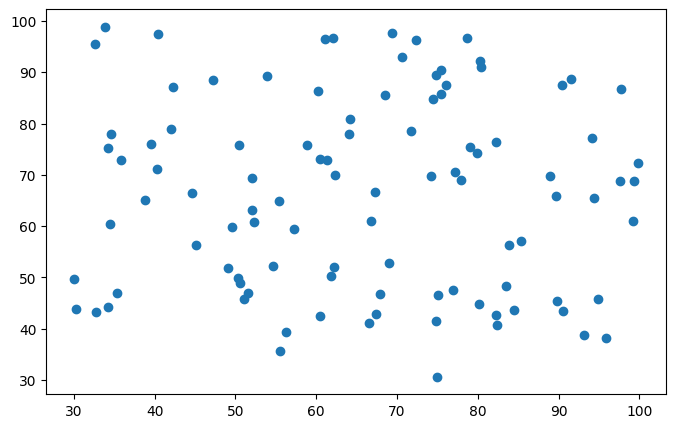

In [2]:
from matplotlib import pyplot as plt
fig1 = plt.figure(figsize=(8,5))
plt.scatter(data.loc[:,'Exam1'],data.loc[:,'Exam2'])
plt.title = 'Exam1-Exam2'
plt.xlabel = 'Exam1'
plt.ylabel = 'Exam2'
plt.show()

In [3]:
# add label mask
mask = data.loc[:,'Pass']==1
~mask

0      True
1      True
2      True
3     False
4     False
      ...  
95    False
96    False
97    False
98    False
99    False
Name: Pass, Length: 100, dtype: bool

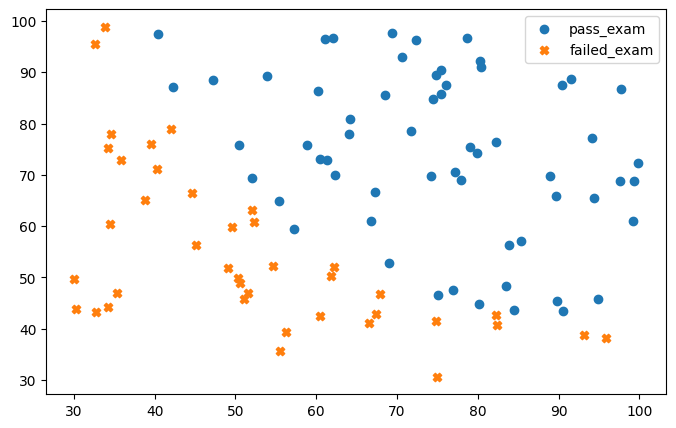

In [4]:
fig2 = plt.figure(figsize=(8,5))
passed = plt.scatter(data.loc[:,'Exam1'][mask],data.loc[:,'Exam2'][mask])
failed = plt.scatter(data.loc[:,'Exam1'][~mask],data.loc[:,'Exam2'][~mask],marker='X')
plt.legend((passed,failed),('pass_exam','failed_exam'))
plt.title = 'Exam1-Exam2'
plt.xlabel = 'Exam1'
plt.ylabel = 'Exam2'
plt.show()

In [5]:
# define x,y
x = data.drop(['Pass'],axis=1)
y = data.loc[:,'Pass']
x1 = data.loc[:,'Exam1']
x2 = data.loc[:,'Exam2']
x1.head()

0    34.623660
1    30.286711
2    35.847409
3    60.182599
4    79.032736
Name: Exam1, dtype: float64

In [6]:
# establish the model and train
from sklearn.linear_model import LogisticRegression
lg1 = LogisticRegression()
lg1.fit(x,y)

LogisticRegression()

In [7]:
y_predict = lg1.predict(x)
print(y_predict)

[0 0 0 1 1 0 1 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 1 0 0 0 0 1
 1 0 0 1 0 1 1 0 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 0 0 0 0 0 1 0 1 1 0 1 1 1
 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 1 1 0 1]


In [8]:
# get accurancy
from sklearn.metrics import accuracy_score
acs = accuracy_score(y,y_predict)
acs

0.89

In [9]:
y_predict1 = lg1.predict([[75,60]])
print('passed' if y_predict1 else 'failed')

passed


/Users/mima0000/anaconda3/envs/ai_tec/lib/python3.11/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [10]:
theta1,theta2 = lg1.coef_[0]
theta0 = lg1.intercept_[0]
theta0,theta1,theta2

(-25.0521931427419, 0.20535491217790391, 0.20058380395469058)

In [11]:
exam2_new = -(theta0+theta1*x1)/theta2
exam2_new

0     89.449169
1     93.889277
2     88.196312
3     63.282281
4     43.983773
        ...    
95    39.421346
96    81.629448
97    23.219064
98    68.240049
99    48.341870
Name: Exam1, Length: 100, dtype: float64

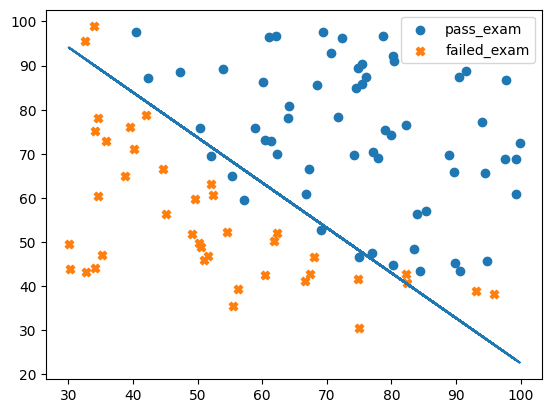

In [12]:
fig3 = plt.figure()
passed = plt.scatter(data.loc[:,'Exam1'][mask],data.loc[:,'Exam2'][mask])
failed = plt.scatter(data.loc[:,'Exam1'][~mask],data.loc[:,'Exam2'][~mask],marker='X')
plt.legend((passed,failed),('pass_exam','failed_exam'))
plt.title = 'Exam1-Exam2'
plt.xlabel = 'Exam1'
plt.ylabel = 'Exam2'
plt.plot(x1,exam2_new)
plt.show()

In [13]:
# create 2dim data
# 这里对x1进行排序是为了最后展示的图片更平滑
x1 = x1.sort_values()

x1_x2 = x1*x2
x1_2 = x1**2
x2_2 = x2**2
x1

63    30.058822
1     30.286711
57    32.577200
70    32.722833
36    33.915500
        ...    
56    97.645634
47    97.771599
51    99.272527
97    99.315009
75    99.827858
Name: Exam1, Length: 100, dtype: float64

In [14]:
# 注意，这个字典里的顺序不能乱
x_new_dic = {'x1':x1,'x2':x2,'x1_2':x1_2,'x2_2':x2_2,'x1_x2':x1_x2}
# 转成模型数据
x_new = pd.DataFrame(x_new_dic)
lg2 = LogisticRegression()
lg2.fit(x_new,y)

LogisticRegression()

In [15]:
y_predict_2d = lg2.predict(x_new)
asc2 = accuracy_score(y,y_predict_2d)
asc2

1.0

In [16]:
# 求解关于x2的二阶边界函数
# 二阶边界函数：
#    theta0+theta1*x1+theta2*x2+theta3*x1^2+theta4*x2^2+theta5*x1*x2 = 0
# 假设x1已知，求x2的方程：先化成: ax^2 + bx + c = 0
#    theta4*x2^2 + (theta5*x1+theta2)*x2 + (theta0+theta1*x1+theta3*x1^2) = 0

theta1,theta2,theta3,theta4,theta5 = lg2.coef_[0]
theta0 = lg2.intercept_[0]
lg2.coef_[0]

array([-8.95942818e-01, -1.40029397e+00, -2.29434572e-04,  3.93039312e-03,
        3.61578676e-02])

In [17]:
a = theta4
b = theta5*x1+theta2
c = theta0+theta1*x1+theta3*x1*x1
x2_new_2d = (-b+np.sqrt(b**2-4*a*c))/(2*a)
x2_new_2d

63    132.124249
1     130.914667
57    119.415258
70    118.725082
36    113.258684
         ...    
56     39.275712
47     39.251001
51     38.963585
97     38.955634
75     38.860426
Name: Exam1, Length: 100, dtype: float64

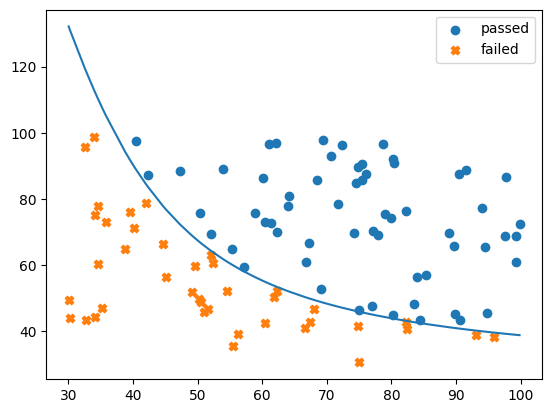

In [19]:
fig4 = plt.figure()
passed = plt.scatter(data.loc[:,'Exam1'][mask],data.loc[:,'Exam2'][mask])
failed = plt.scatter(data.loc[:,'Exam1'][~mask],data.loc[:,'Exam2'][~mask],marker='X')
plt.legend((passed,failed),('passed','failed'))
plt.plot(x1,x2_new_2d)
plt.show()